# Results on the part

The inspection results from [`02-inspection-report`](02-inspection-report.ipynb),
colored onto the 3D part, one part at a time or the worst of all 15.

Setup is in the [README](../README.md).

## Setup


`%autoreload 2` re-reads [`qifkit.py`](qifkit.py) before every cell, so an edit
to it takes effect without restarting the kernel.

`qifkit.start_viewer` starts the 3D viewer's server up front; its comments say why
that has to happen before the first plot.

In [6]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

import qifkit

pd.set_option('display.width', 140)

import pyvista as pv

await qifkit.start_viewer()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
MODEL = '000454_D-MV-FH-2'
doc = qifkit.load(MODEL)

# The cleaned, labeled table from 02-inspection-report, in one call.
clean = qifkit.results(doc)
unit = qifkit.linear_unit(doc)

print(f'{MODEL}: {len(clean)} rows, {clean.serial.nunique()} parts, '
      f'{clean.label.nunique()} characteristics')

000454_D-MV-FH-2: 465 rows, 15 parts, 31 characteristics


## Back onto the part

Notebooks 02 and 03 were tables and charts. Now the same numbers go onto the geometry,
through `qif_id`, exactly the join [`01-tolerance-tightness`](01-tolerance-tightness.ipynb) uses. **Putting a
tolerance on a face and putting a measurement on a face is the same join.**

In [8]:
# Same call the tolerance notebook makes, on the same document we just read the
# results out of. Meshing the document we parsed is what makes a mesh/QIF
# mismatch impossible rather than merely checked.
mesh, mesh_arrays = qifkit.tessellate(doc)
qif_ids = mesh_arrays['qif_id']

print(f'{mesh.n_cells} cells over {len(np.unique(qif_ids))} faces, units {unit}')

31926 cells over 65 faces, units mm


In [9]:
# A face can be controlled by several characteristics. The one that matters is
# whichever has consumed the most of its band, so take the worst per face.
def worst_per_entity(rows):
    worst = {}
    for entities, fraction in zip(rows.entities, rows.fraction.abs()):
        for entity in entities:
            entity = int(entity)
            if fraction > worst.get(entity, 0):
                worst[entity] = fraction
    return worst


serials = sorted(clean.serial.unique(), key=qifkit.serial_key)

for serial in serials:
    worst = worst_per_entity(clean[clean.serial == serial])
    # NaN where a face carries no measured characteristic (shown gray; normal).
    mesh.cell_data[serial] = np.array([worst.get(int(i), np.nan) for i in qif_ids])

measured_faces = np.count_nonzero(~np.isnan(mesh.cell_data[serials[0]]))
print(f'{len(serials)} parts; {measured_faces} of {mesh.n_cells} cells carry a measured result '
      f'({len(np.unique(qif_ids[~np.isnan(mesh.cell_data[serials[0]])]))} faces)')

# nanmax over a cell that is NaN for every part warns instead of returning NaN,
# so mask those cells.
per_part = np.vstack([mesh.cell_data[s] for s in serials])
worst_overall = np.full(mesh.n_cells, np.nan)
measured = ~np.isnan(per_part).all(axis=0)
worst_overall[measured] = np.nanmax(per_part[:, measured], axis=0)
mesh.cell_data['worst of all parts'] = worst_overall
print(f'worst fraction of band seen anywhere: {np.nanmax(worst_overall):.2f}')

15 parts; 26122 of 31926 cells carry a measured result (35 faces)
worst fraction of band seen anywhere: 6.76


**What the color means.** Each face takes the worst measured characteristic on it.
Green is comfortably inside tolerance, yellow is using most of its band, red is at
or past a limit. **Gray** faces have no measured characteristic. This is normal, since a
CMM measures features, not every surface.

**What the slider does.** It chooses which manufactured part you are looking at.
`0` shows the worst result each face had across all 15 parts; `1` to `15` show one
part at a time. Faces that stay red on every
part are the systematic failures from the pivot table; faces whose color changes
show part-to-part variation.

**Bigger view.** The link under the viewer opens it in its own browser tab. Press
F11 there for the full screen.

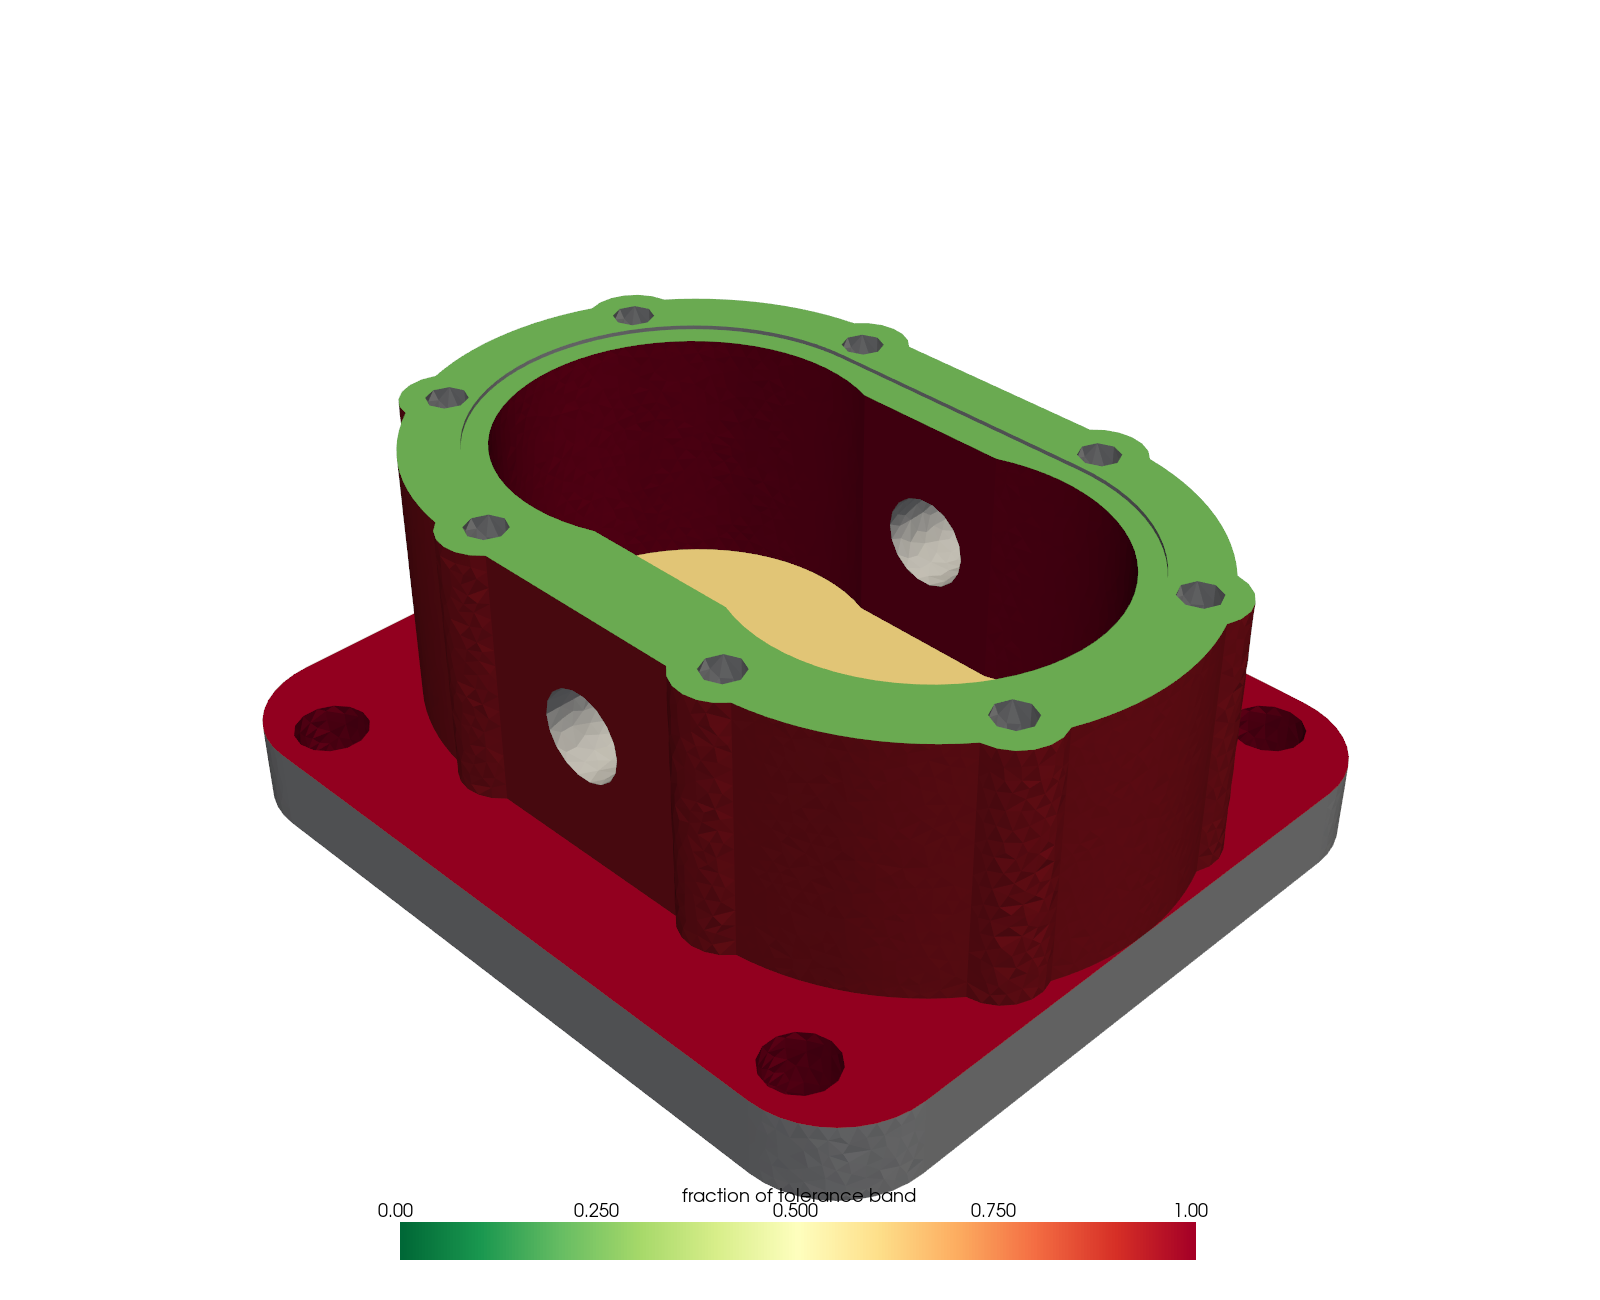

In [10]:
# 1.0 is exactly on the limit, so the scale stops there and anything beyond is
# clamped to the top color: past the limit, how far past stops being the point.
CLIM = (0.0, 1.0)
CMAP = 'RdYlGn_r'

views = ['worst of all parts'] + serials   # slider 0 is the worst case, 1-15 the parts

pl = pv.Plotter()
actor = pl.add_mesh(mesh, scalars=views[0], cmap=CMAP, clim=CLIM, nan_color='lightgray',
                    scalar_bar_args={'title': 'fraction of tolerance band', 'n_labels': 5})
pl.add_text('gray = not measured', position='lower_left', font_size=9, name='legend')


def title(index):
    return ('Worst result on each face, across all parts' if index == 0
            else f'Part {views[index]}')


pl.add_text(title(0), position='upper_left', font_size=11, name='title')


def show_view(value):
    # Slider callback: recolor the mesh with the chosen part's results. Replacing
    # a text actor by the same `name` keeps one title rather than stacking them.
    index = int(round(value))
    mesh.set_active_scalars(views[index])
    actor.mapper.array_name = views[index]
    actor.mapper.scalar_range = CLIM
    pl.add_text(title(index), position='upper_left', font_size=11, name='title')


pl.add_slider_widget(show_view, [0, len(serials)], value=0, title='part  (0 = worst of all)',
                     fmt='%.0f', style='modern', pointa=(0.55, 0.9), pointb=(0.95, 0.9))

qifkit.show(pl, fallback_png='04-results-on-the-part.png')